In [1]:
import os
from astropy.io import fits
from astropy.table import Table
import numpy as np
from scipy import signal
import scipy.constants as const
import matplotlib.pyplot as plt
import paths

In [4]:
def gaussian(p, x):
    """ Compute a gaussian distribution at the points x.
        p is a three- or four-component array, list, or tuple:

        y =  [p3 +] p0/(p1*sqrt(2pi)) * exp(-(x-p2)**2 / (2*p1**2))

        p[0] -- Area of the gaussian
        p[1] -- one-sigma dispersion
        p[2] -- central offset (mean location)
        p[3] -- optional constant, vertical offset

        NOTE: FWHM = 2*sqrt(2*ln(2)) * p1  ~ 2.3548*p1

        SEE ALSO:  egaussian"""
    #2008-09-11 15:11 IJC: Created for LINEPROFILE
    # 2011-11-10 12:00 IJMC: Don't copy x or p inputs; fiddled with
    # background addition and ordering of operations
    # 2012-12-23 12:12 IJMC: Made it a tad faster.
    
    if not isinstance(x, np.ndarray):
        x = np.array(x, dtype=float, copy=False)

    y = p[0]/(p[1]*np.sqrt(2*np.pi)) * np.exp(-0.5 * ((x-p[2])/p[1])**2)

    if len(p)>3:
        y += p[3]
    
    return y

def putvecsinarray(vecs):
    """Take a tuple, list, or array of 1D arrays and always return their 
       Vstacked combination.  (Just a helper function, folks!)
    """
    # 2017-04-19 12:28 IJMC: Created
    
    if isinstance(vecs,tuple) or isinstance(vecs,list):
        vecs = np.vstack(vecs).transpose()
    elif isinstance(vecs, np.ndarray) and vecs.ndim < 2:
        vecs = vecs.reshape(len(vecs),1)
    else:
        vecs = np.array(vecs, copy=False)
    return vecs

def polyfitr(x, y, N, s, fev=100, w=None, diag=False, clip='both', \
                 verbose=False, plotfit=False, plotall=False, eps=1e-13, catchLinAlgError=False, xerr=None, yerr=None, retodr=False, checkvals=True):
    """Matplotlib's polyfit with weights and sigma-clipping rejection.

    :DESCRIPTION:
      Do a best fit polynomial of order N of y to x.  Points whose fit
      residuals exeed s standard deviations are rejected and the fit is
      recalculated.  Return value is a vector of polynomial
      coefficients [pk ... p1 p0].

    :OPTIONS:
        w: a set of weights for the data; uses CARSMath's weighted
             polynomial fitting routine instead of numpy's standard
             polyfit.  
             NOTE: if using errors in both x and y ("orthogonal
             distance regression") then don't set w --- instead set
             xerr and yerr (see below).

        fev:  number of function evaluations to call before stopping

        'diag'nostic flag:  Return the tuple (p, chisq, n_iter)

        clip: 'both' -- remove outliers +/- 's' sigma from fit
              'above' -- remove outliers 's' sigma above fit
              'below' -- remove outliers 's' sigma below fit
              'None'/None -- no  outlier removal

        xerr/yerr : one-sigma uncertainties in x and y. If these are
                    set, you are committing to an "orthogonal distance regression"

        retodr : bool
          If True, return the tuple (parameters, scipy_ODR_object)

        catchLinAlgError : bool
          If True, don't bomb on LinAlgError; instead, return [0, 0, ... 0].

    :REQUIREMENTS:
       :doc:`CARSMath`

    :NOTES:
       Iterates so long as n_newrejections>0 AND n_iter<fev.

    """
    # 2008-10-01 13:01 IJC: Created & completed
    # 2009-10-01 10:23 IJC: 1 year later! Moved "import" statements within func.
    # 2009-10-22 14:01 IJC: Added 'clip' options for continuum fitting
    # 2009-12-08 15:35 IJC: Automatically clip all non-finite points
    # 2010-10-29 09:09 IJC: Moved pylab imports inside this function
    # 2012-08-20 16:47 IJMC: Major change: now only reject one point per iteration!
    # 2012-08-27 10:44 IJMC: Verbose < 0 now resets to 0
    # 2013-05-21 23:15 IJMC: Added catchLinAlgError
    # 2017-05-12 11:37 IJMC: Added option for orthogonal distance regression
    
    #from CARSMath import polyfitw
    #from numpy import polyfit, polyval
    from numpy.linalg import LinAlgError
    #from pylab import plot, legend, title, figure

    import scipy.odr as odr
    
    if verbose < 0:
        verbose = 0

    xx = np.array(x, copy=False)
    yy = np.array(y, copy=False)
    noweights = (w is None) and (xerr is None) and (yerr is None)
    if noweights:
        ww = np.ones(xx.shape, float)
    else:
        ww = np.array(w, copy=False)

    fitxy = False
    if xerr is None and yerr is not None:
        w = 1./np.array(yerr)**2
    elif xerr is not None and yerr is not None:
        fitxy = True
        xerr = putvecsinarray(xerr).ravel()
        yerr = putvecsinarray(yerr).ravel()
        
    ii = 0
    nrej = 1

    if checkvals:
        goodind = np.isfinite(xx)*np.isfinite(yy)
        if noweights:
            pass
        elif fitxy:
            goodind *= (np.isfinite(xerr) * np.isfinite(yerr))
        else:
            goodind *= np.isfinite(ww)

        xx2 = xx[goodind]
        yy2 = yy[goodind]
        if fitxy:
            xerr2 = xerr[goodind]
            yerr2 = yerr[goodind]
        else:
            ww2 = ww[goodind]

            
    if fitxy:
        poly_model = odr.Model(np.polyval)
        guess = polyfitr(xx2,yy2, N, s=s, fev=fev, w=1./yerr2**2)
    
    while (ii<fev and (nrej!=0)):
        if noweights:
            p = np.polyfit(xx2,yy2,N)
            residual = yy2 - np.polyval(p,xx2)
            stdResidual = np.std(residual)
            clipmetric = s * stdResidual
        else:
            if fitxy:
                data = odr.RealData(xx2, yy2, sx=xerr2, sy=yerr2)
                odrobj = odr.ODR(data, poly_model, beta0=guess, maxit=10000)
                odrout = odrobj.run()
                p = odrout.beta
                residual = np.sqrt((odrout.delta / xerr2)**2 + (odrout.eps / yerr2)**2)
                guess = p.copy()

            else:
                if catchLinAlgError:
                    try:
                        #p = np.polyfitw(xx2,yy2, ww2, N)
                        p = np.polyfit(xx2, yy2, N, w=np.sqrt(ww2))
                    except LinAlgError:
                        p = np.zeros(N+1, dtype=float)
                else:
                    #p = polyfitw(xx2,yy2, ww2, N)
                    p = np.polyfit(xx2, yy2, N, w=np.sqrt(ww2))

                #p = p[::-1]  # polyfitw uses reverse coefficient ordering
                
                residual = (yy2 - np.polyval(p,xx2)) * np.sqrt(ww2)
                
            clipmetric = s

        if clip=='both':
            worstOffender = abs(residual).max()
            #pdb.set_trace()
            if worstOffender <= clipmetric or worstOffender < eps:
                ind = np.ones(residual.shape, dtype=bool)
            else:
                ind = abs(residual) < worstOffender
        elif clip=='above':
            worstOffender = residual.max()
            if worstOffender <= clipmetric:
                ind = np.ones(residual.shape, dtype=bool)
            else:
                ind = residual < worstOffender
        elif clip=='below':
            worstOffender = residual.min()
            if worstOffender >= -clipmetric:
                ind = np.ones(residual.shape, dtype=bool)
            else:
                ind = residual > worstOffender
        else:
            ind = np.ones(residual.shape, dtype=bool)
    
        xx2 = xx2[ind]
        yy2 = yy2[ind]
        if fitxy:
            xerr2 = xerr2[ind]
            yerr2 = yerr2[ind]
        elif (not noweights):
            ww2 = ww2[ind]
        ii = ii + 1
        nrej = len(residual) - len(xx2)
        if plotall:
            plt.figure()
            plt.plot(x,y, '.', xx2,yy2, 'x', x, np.polyval(p, x), '--')
            plt.legend(['data', 'fit data', 'fit'])
            plt.title('Iter. #' + str(ii) + ' -- Close all windows to continue....')

        if verbose:
            print( str(len(x)-len(xx2)) + ' points rejected on iteration #' + str(ii))

    if (plotfit or plotall):
        plt.figure()
        plt.plot(x,y, '.', xx2,yy2, 'x', x, np.polyval(p, x), '--')
        plt.legend(['data', 'fit data', 'fit'])
        plt.title('Close window to continue....')

    if diag:
        chisq = ( (residual)**2 / yy2 ).sum()
        p = (p, chisq, ii)

    if retodr:
        ret = p, odrout
    else:
        ret = p
    return ret

def rotationalProfile(delta_epsilon, delta_lam):
    """Compute the rotational profile of a star, assuming solid-body
    rotation and linear limb darkening.

    This uses Eq. 18.14 of Gray's Photospheres, 2005, 3rd Edition.

    :INPUTS:

      delta_epsilon : 2-sequence

        [0] : delta_Lambda_L = lambda * V * sin(i)/c; the rotational
              displacement at the stellar limb.

        [1] : epsilon, the linear limb darkening coefficient, used in
              the relation I(theta) = I0 + epsilon * (cos(theta) - 1).

        [2] : OPTIONAL! The central location of the profile (otherwise
              assumed to be located at delta_lam=0).

      delta_lam : scalar or sequence
        Wavelength minus offset: Lambda minus lambda_0.  Grid upon
        which computations will be done.

    :EXAMPLE:
      ::

        import pylab as py
        import spec

        dlam = py.np.linspace(-2, 2, 200) # Create wavelength grid
        profile = spec.rotationalProfile([1, 0.6], dlam)

        py.figure()
        py.plot(dlam, profile)
    """
    # 2013-05-26 10:37 IJMC: Created.

    delta_lambda_L, epsilon = delta_epsilon[0:2]
    if len(delta_epsilon)>2:  # optional lambda_offset
        lamdel2 = 1. - ((delta_lam - delta_epsilon[2])/delta_lambda_L)**2
    else:
        lamdel2 = 1. - (delta_lam/delta_lambda_L)**2
    
    if not hasattr(delta_lam, '__iter__'):
        delta_lam = np.array([delta_lam])

    ret = (4*(1.-epsilon) * np.sqrt(lamdel2) + np.pi*epsilon*lamdel2) / \
        (2*np.pi * delta_lambda_L * (1. - epsilon/3.))    

    ret[lamdel2<0] = 0.

    return ret

def modelspec_tel_template2(params, lam_template, template, lam_atmo, atmo, NPW, NPC, npix, retlam=False):
    """    
     :INPUTS:
       params:      

          [0]: vsini for rotational broadening profile, in units of km/s.
               (See :func:`spec.rotationalProfile`)

          [1]: linear limb darkening coefficient for rotational
               broadening profile. (See :func:`spec.rotationalProfile`)

          [2]: rv of target divided by speed of light, (rv/c)

          [3]: fwhm for (Gaussian) instrumental profile convolution,
               in units of km/s.

          [4]: effective scaling of telluric transmission specturm in
              'atmo'.  This will be scaled as: 1.0 - (scale*(1.0 -
              atmo)). After convolution, any negative values will be
              set to zero. Thus line-broadening is explicitly *not*
              treated correctly.

          [5:5+NPW]: the wavelength solution coefficients. These will
                     be passed to numpy.polyval with the vector
                     "arange(npix)/npix"

          [5+NPW:5+NPW+NPC]: the flux normalization
                     coefficients. These will also be passed to
                     numpy.polyval with the vector "arange(npix)/npix"

       lam_template: wavelength scale of input template. Ideally this
                       is more finely sampled than lam.

       template: template SED: the unbroadened, assumed-known spectrum
                   for this object. Ideally, this will have rather
                   broader coverage, and higher spectral resolution,
                   than the desired model.

       lam_atmo: wavelength scale of input telluric transmission
                       spectrum. Ideally this is more finely sampled
                       than the desired output wavelength scale.

       atmo: template of telluric transmission. Ideally, this will
                   have higher spectral resolution than the spectrum
                   you wish to model.

       NPW : int
         number of polynomial coefficients for wavelength solution.

       NPC : int
         number of polynomial coefficients for continuum correction.

       npix : int
         Number of pixels in modeled spectrum.

       retlam : bool
         If True, return the tuple (model, spectrum).

       :EXAMPLE:
         ::

            XXX update this for vsini/LLD case!!!

            NPW = 3
            npix = wobs.size
            pix = np.arange(npix, dtype=float)/npix
            wcoef = np.polyfit(pix, wobs, NPW-1)
            ccoef = [1./np.median(template)]
            NPC = len(ccoef)
            guess = np.concatenate(([17, 1e-4, 9, 1], wcoef, ccoef))

            mygmod, mygw = fit_atmo.modelspec_tel_template(guess, lam_template, template, lam_atmo, atmo, NPW, NPC, npix, retlam=True)

       Things like flux conservation and line-broadening are not
       well-treated in this function!
       """
    # 2013-05-08 07:38 IJMC: Created
    # 2013-08-06 10:28 IJMC: Updated to use vsini and LLD
    import pdb

    vsini = params[0]
    lld = params[1]
    rv = params[2]
    instrument_profile_fwhm_kms = params[3] # km/s
    if params[4]<0:
        atmo_scale = 0
    else:
        atmo_scale = params[4]

    if vsini<0:
        vsini = 0

    wavelength_coefs = params[5:5+NPW]
    continuum_coefs = params[5+NPW:5+NPW+NPC]
    
    lam_template = np.array(lam_template, copy=False)
    template = np.array(template, copy=False)
    lam_atmo = np.array(lam_atmo, copy=False)
    atmo = np.array(atmo, copy=False)

    if lam_template.shape!=template.shape or lam_template.ndim!=1:
        return -1
    if lam_atmo.shape!=atmo.shape:
        return -1
        
    pix = np.arange(npix, dtype=float)/npix
    lam = np.polyval(wavelength_coefs, pix)

    # Create model-convolution Kernel and convolve template:
    pixsize_ms = np.diff(lam_template).mean()/lam_template.mean() * const.c
    xkern = np.arange(-int(1200.*vsini/pixsize_ms), int(1200.*vsini/pixsize_ms)+1)
    if xkern.size>=template.size:
        xkern = np.arange(-template.size/2, template.size/2)

    if xkern.size<=1:
        rotational_profile = np.array([1])
    else:
        dv = xkern * pixsize_ms
        rotational_profile = rotationalProfile([vsini*1000., lld, 0], dv)
        rotational_profile /= rotational_profile.sum()
        #kern = gaussian([1., fwhm/2.3548, 0, 0], xkern)

    #pdb.set_trace()
    new_template = np.convolve(template, rotational_profile, 'same')

    # Scale the telluric spectrum.
    new_atmo = 1.0 - atmo_scale*(1.0 - atmo)
    new_atmo[new_atmo<0] = 0.

    # Shift template to specified RV & interpolate to wavelength grid
    #pdb.set_trace()
    new_template = np.interp(lam, lam_template*(1.+rv), new_template, left=0., right=0.)
    output = new_template * np.interp(lam, lam_atmo, new_atmo, left=0., right=0.)

    # Convolve by appropriate Insturment Profile:
    new_pixsize_ms = np.diff(lam).mean()/lam.mean() * const.c
    ip_xkern = np.arange(-int(1200. * instrument_profile_fwhm_kms/new_pixsize_ms), int(1200.*instrument_profile_fwhm_kms/new_pixsize_ms)+1)
    if ip_xkern.size>=output.size:
        ip_xkern = np.arange(-output.size/2, output.size/2)
    if ip_xkern.size<=1:
        instrument_profile = np.array([1])
    else:
        instrument_profile = gaussian([1., (1000./2.3548) * (instrument_profile_fwhm_kms/new_pixsize_ms), 0, 0], ip_xkern)
        instrument_profile /= instrument_profile.sum()

    output = np.convolve(output, instrument_profile, 'same')

    # Multiply by appropriate normalization polynomial
    output *= np.polyval(continuum_coefs, pix)
    output[output < 0] = 0.

    if retlam:
        ret = (output, lam)
    else: 
        ret = output
        
    return ret

def modelspec_tel_template(params, lam_template, template, lam_atmo, atmo, NPW, NPC, npix, retlam=False):
    """
    Return the rotationally-broadened, rv-shifited, telluric-corrected model spectrum.

     :INPUTS:
       params:      

          [0]: vsini for rotational broadening profile, in units of km/s.
               (See :func:`spec.rotationalProfile`)

          [1]: linear limb darkening coefficient for rotational
               broadening profile. (See :func:`spec.rotationalProfile`)

          [2]: rv of target divided by speed of light, (rv/c)

          [3]: fwhm for telluric convolution, in units of PIXELS of
               lam_atmo. (This may not be ideal if your wavelength
               scale in 'lam_atmo' changes rapidly).

          [4]: effective scaling of telluric transmission specturm in
              'atmo'.  This will be scaled as: 1.0 - (scale*(1.0 -
              atmo)). After convolution, any negative values will be
              set to zero. Thus line-broadening is explicitly *not*
              treated correctly.

          [5:5+NPW]: the wavelength solution coefficients. These will
                     be passed to numpy.polyval with the vector
                     "arange(npix)/npix"

          [5+NPW:5+NPW+NPC]: the flux normalization
                     coefficients. These will also be passed to
                     numpy.polyval with the vector "arange(npix)/npix"

       lam_template: wavelength scale of input template. Ideally this
                       is more finely sampled than lam.

       template: template SED: the unbroadened, assumed-known spectrum
                   for this object. Ideally, this will have rather
                   broader coverage, and higher spectral resolution,
                   than the desired model.

       lam_atmo: wavelength scale of input telluric transmission
                       spectrum. Ideally this is more finely sampled
                       than the desired output wavelength scale.

       atmo: template of telluric transmission. Ideally, this will
                   have higher spectral resolution than the spectrum
                   you wish to model.

       NPW : int
         number of polynomial coefficients for wavelength solution.

       NPC : int
         number of polynomial coefficients for continuum correction.

       npix : int
         Number of pixels in modeled spectrum.

       retlam : bool
         If True, return the tuple (model, spectrum).

       :EXAMPLE:
         ::

            XXX update this for vsini/LLD case!!!

            NPW = 3
            npix = wobs.size
            pix = np.arange(npix, dtype=float)/npix
            wcoef = np.polyfit(pix, wobs, NPW-1)
            ccoef = [1./np.median(template)]
            NPC = len(ccoef)
            guess = np.concatenate(([17, 1e-4, 9, 1], wcoef, ccoef))

            mygmod, mygw = fit_atmo.modelspec_tel_template(guess, lam_template, template, lam_atmo, atmo, NPW, NPC, npix, retlam=True)

       Things like flux conservation and line-broadening are not
       well-treated in this function!
       """
    # 2013-05-08 07:38 IJMC: Created
    # 2013-08-06 10:28 IJMC: Updated to use vsini and LLD
    import pdb
    #import spec

    vsini = params[0]
    lld = params[1]
    rv = params[2]
    atmo_fwhm = params[3]
    if params[4]<0:
        atmo_scale = 0
    else:
        atmo_scale = params[4]

    if vsini<0:
        vsini = 0

    wavelength_coefs = params[5:5+NPW]
    continuum_coefs = params[5+NPW:5+NPW+NPC]
    
    lam_template = np.array(lam_template, copy=False)
    template = np.array(template, copy=False)
    lam_atmo = np.array(lam_atmo, copy=False)
    atmo = np.array(atmo, copy=False)

    if lam_template.shape!=template.shape or lam_template.ndim!=1:
        return -1
    if lam_atmo.shape!=atmo.shape:
        return -1
        
    pix = np.arange(npix, dtype=float)/npix

    # Create model-convolution Kernel and convolve template:
    pixsize_ms = np.diff(lam_template).mean()/lam_template.mean() * const.c
    xkern = np.arange(-int(1200.*vsini/pixsize_ms), int(1200.*vsini/pixsize_ms)+1)

    
    if xkern.size>=template.size:
        xkern = np.arange(-template.size/2, template.size/2)

    if xkern.size<=1:
        rotational_profile = np.array([1])
    else:
        dv = xkern * pixsize_ms
        rotational_profile = rotationalProfile([vsini*1000., lld, 0], dv)
        rotational_profile /= rotational_profile.sum()
        #kern = gaussian([1., fwhm/2.3548, 0, 0], xkern)
        #kern /= kern.sum()
    
    new_template = np.convolve(template, rotational_profile, 'same')

    # Create telluric-convolution Kernel and convolve scaled telluric spectrum:
    new_atmo = 1.0 - atmo_scale*(1.0 - atmo)
    xkern = np.arange(int(-5*atmo_fwhm), int(5*atmo_fwhm))
    if xkern.size>=new_atmo.size:
        xkern = np.arange(-new_atmo.size/2, new_atmo.size/2)

    if xkern.size<=1:
        pass
    else:
        kern = gaussian([1., atmo_fwhm/2.3548, 0, 0], xkern)
        kern /= kern.sum()
        new_atmo = np.convolve(new_atmo, kern, 'same')

    new_atmo[new_atmo<0] = 0.

    # Shift template to specified RV & interpolate to wavelength grid
    #pdb.set_trace()
    lam = np.polyval(wavelength_coefs, pix)
    new_template = np.interp(lam, lam_template*(1.+rv), new_template, left=0., right=0.)
    output = new_template * np.interp(lam, lam_atmo, new_atmo, left=0., right=0.)

    # Multiply by appropriate normalization polynomial
    output *= np.polyval(continuum_coefs, pix)


    if retlam:
        ret = (output, lam)
    else: 
        ret = output
        
    return ret

In [3]:
_model = './'
pmod = 'output'
#npix = wobs.shape[1]

dloglam = .02 # 50./2300.
npix = 2048
vsini = 20. # km/s
LLD = 0.5 # linear limb darkening coefficient
RV = 0./3e5  # km/s, target relative to telluric
#atmo_fwhm_pix = 5. # pixels; fix this!
resolution = 50000 # spectral resolution
#lambda_factor = 0.004 # lambda^2 / (R * d_{lam_FSR})
telluric_scaling = 1.
NPW = 2
NPC = 1

pix_arcsec = 0.1 # arcsec per pixel
slitwidth = 0.2 # arcsec
pix_sr = (0.1 / 206265)**2 # steradian
total_efficiency = 0.1
readnoise = 10. # electrons
itime = 1200 # sec
nrows = 10 # detector rows
diameter = 820. #  cm, diameter
distance = 2  # parsecs
radius = 1  # Jupiter radii


minlam = 0.785
maxlam = 5.4
#minlam, maxlam = 1.2, 1.3
area = np.pi * (diameter/2.)**2 # cm^2

plotalot=True
fs = 16

model: (2, 1215822)
[[0.00000000e+00 1.00000000e-07 2.00000000e-07 ... 9.98226967e+02
  9.98726830e+02 9.99226693e+02]
 [2.58821000e-93 2.58821000e-93 2.58821000e-93 ... 3.79822000e-02
  4.06471000e-02 4.24004000e-02]], 

telluric transmission: (2, 1236873)
[[0.5000001  0.50000064 0.50000122 ... 5.4810339  5.48106274 5.48109098]
 [1.0036     1.0077     0.99631    ... 0.         0.01679    0.017434  ]], 
sky background:
[[9.000000e-01 9.000200e-01 9.000400e-01 ... 5.599940e+00 5.599960e+00
  5.599980e+00]
 [1.315709e+00 1.339856e+00 1.361948e+00 ... 1.054710e+06 1.056777e+06
  1.058943e+06]]


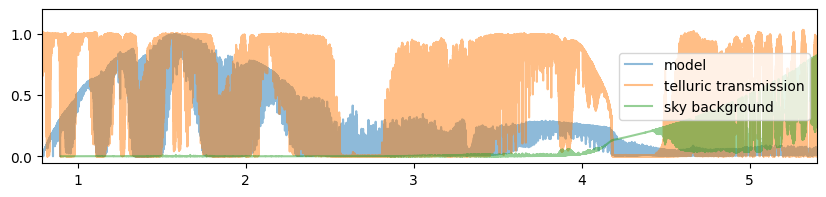

In [5]:
homedir = os.path.expanduser('~')

if False:
    modelfn = homedir + '/uoedrive/data/BTSettlModels/CIFIST2015/lte015.0-5.0-0.0a+0.0.BT-Settl.spec.fits'
    header = fits.open(modelfn)[1].header # erg/s/cm2/micron
    mod = Table.read(modelfn, format='fits')
    mod['wl'] = mod['Wavelength']
    mod['flux'] = mod['Flux'] # W/m2/um
    model = np.array([mod['wl'], mod['flux']*1e3]) # convert flux from W/m2/um to erg/s/cm2/um
    print(f"model flux units: {header['TUNIT2']}")

if True:
    modelfn = homedir + '/uoedrive/data/bt-settl/lte008-5.0-0.0.BT-Settl.7.dat.txt'
    modelfn = homedir + '/uoedrive/data/bt-settl-cifist/lte014.0-5.0-0.0a+0.0.BT-Settl.spec.7.dat.txt'
    #modelfn = homedir + '/uoedrive/data/bt-settl-agss/lte014-5.0-0.0.BT-Settl.7.dat.txt'
    model = np.loadtxt(modelfn).T
    model[0] *= 1e-4 # A to um
    model[1] *= 1e4  # erg/s/cm2/A to erg/s/cm2/um

telfn = paths.data / 'telluric/transdata_0,5-5_mic.fits' #transdata_2,28-2,37_mic_hires.fits'
#telfn = homedir + '/uoedrive/data/telluric/transdata_0,5-14_mic_hires.fits'
#telradfn = '/Users/ianc/proj/pcsa/data/atmo/raddata_1,5-5,5_losres_erg-s-cm2-um-sr.fits'
telradfn = paths.data / 'telluric/mauna_kea_emission_h2o=16_airmass=1,5_photon-sec-arcsec2-nm-m2.fits'
#telradfn = "mk_skybg_zm_16_15_ph.dat"

atm0 = fits.getdata(telfn).T
radatm0 = fits.getdata(telradfn)

#atm0 = fits.getdata(telfn)[:1800000].T
#radatm0 = np.loadtxt(telradfn).T

print(f"model: {model.shape}\n{model}, \n")
print(f"telluric transmission: {atm0.shape}\n{atm0}, \nsky background:\n{radatm0}")

plt.figure(figsize=[10, 2])
plt.plot(model[0], model[1]/np.max(model[1]), label='model', alpha=0.5)
plt.plot(atm0[0], atm0[1], label='telluric transmission', alpha=0.5)
plt.plot(radatm0[0], radatm0[1]/np.max(radatm0[1]), label='sky background', alpha=0.5)
plt.xlim(minlam, maxlam)
plt.legend()

In [6]:
nbins = np.ceil(np.log10(maxlam/minlam) / np.log10(1. + dloglam)).astype(int)
lam_centers = minlam * (1. + dloglam)**np.arange(nbins)
#print(f"nbins: {nbins}\nlam_centers:\n{lam_centers}")
rjup = 7.1492e7 # Jupiter equatorial radius in m
pc = 3.08568025e16 # parsec in meters
#geometric_scalefactor = np.pi * ((radius * rjup)/(distance * pc))**2 # sr
geometric_scalefactor = ((radius * rjup)/(distance * pc))**2
ew = np.zeros(nbins)
ew_dao = np.zeros(nbins)
median_flux = np.zeros(nbins)
median_atmo = np.zeros(nbins)
median_skyflux = np.zeros(nbins)
median_snr = np.zeros(nbins)
median_ron = np.zeros(nbins)
median_telobs = np.zeros(nbins)

for jj in range(nbins):
    #lolim, hilim = lam_lims[jj]
    lolim = lam_centers[jj] * (1. - dloglam/2.)
    hilim = lam_centers[jj] * (1. + dloglam/2.)
    #print(f"Bin {jj}: {lolim:.3f} - {hilim:.3f} microns")

    tind = (model[0]>lolim) * (model[0] < hilim)
    lam_template = model[0,tind]
    template = model[1,tind]

    #template /= np.median(template)
    aind = (atm0[0]>lolim) * (atm0[0] < hilim)
    true_atmo = atm0[1,aind]
    true_lam_atmo = atm0[0,aind]
    lam_atmo = lam_template.copy()
    atmo = np.ones(lam_atmo.size)

    lam_poly = [(hilim-lolim), lolim]
    params = [vsini, LLD, RV, 3e5/resolution, telluric_scaling] + lam_poly + [1]
    observation, lam = modelspec_tel_template2(params, lam_template, template, lam_atmo, atmo, NPW, NPC, npix, retlam=True)
    telluric_observation, tel_lam = modelspec_tel_template2(params, lam_template, template, true_lam_atmo, true_atmo, NPW, NPC, npix, retlam=True)

    goodind = ((observation>0).nonzero()[0][0], -(observation[::-1]>0).nonzero()[0][0]-1)
    lam = lam[goodind[0]:goodind[-1]]
    observation = observation[goodind[0]:goodind[-1]] # erg/s/cm2/micron
    telluric_observation = telluric_observation[goodind[0]:goodind[-1]] # erg/s/cm2/micron
    dlam = np.concatenate([[0], np.diff(lam)])
    #print("average dlam:", np.median(dlam))
    x1, x2 = 1200, 1210

    c_si = 299792458  # speed of light, m/s
    h = 6.626068e-34 # SI units: Planck's constant
    photon_energy = h * c_si/(lam * 1e-6) * 1e7 # erg / photon
    telluric_observation *= (geometric_scalefactor / photon_energy) # photon/s/cm2/micron
    # phot/sec/arcsec2/nm/m2'
    lo_background_flam = np.interp(lam, radatm0[0], radatm0[1]) # 
    lo_background = lo_background_flam * slitwidth * pix_arcsec * dlam * 1000/ 1e4 # phot/sec/pixel/cm2

    integration = telluric_observation * itime * area * total_efficiency * dlam # photons per detector column
    sky_flux = lo_background * itime * area # photons per detector column
    ron_term = (readnoise*nrows)**2
    snr = integration / np.sqrt(integration + sky_flux + (readnoise*nrows)**2)

    xpix = np.linspace(0, 1, lam.size)
    #cfit = np.polyfit(lam, observation, 2) #, 0.5, clip='below', fev=lam.size*0.8)
    cfit = polyfitr(lam, observation, 2, 0.5, clip='below', fev=lam.size*0.8)
    pspec_cont = np.polyval(cfit, lam)
    pspec_cont[pspec_cont<np.sort(observation)[int(lam.size*0.01)]] = observation[pspec_cont<np.sort(observation)[int(lam.size*0.01)]]
    pspec_cont[pspec_cont<observation] = observation[pspec_cont<observation]
    pspec_cont = signal.medfilt(pspec_cont, 101)

    dlam = np.concatenate([[0], np.diff(lam)])
    ew[jj] = (1e4*dlam * (1. - observation / pspec_cont)).sum()
    median_telobs[jj] = np.median(telluric_observation)
    median_flux[jj] = np.median(integration)
    median_skyflux[jj] = np.median(sky_flux)
    median_snr[jj] = np.median(snr)
    median_atmo[jj] = np.median(true_atmo)
    median_ron[jj] = np.median(ron_term)

/var/folders/jm/dmx123p56254c5gy18wgtyh00000gn/T/ipykernel_44549/4158427168.py:282: RuntimeWarning: invalid value encountered in sqrt
  ret = (4*(1.-epsilon) * np.sqrt(lamdel2) + np.pi*epsilon*lamdel2) / \


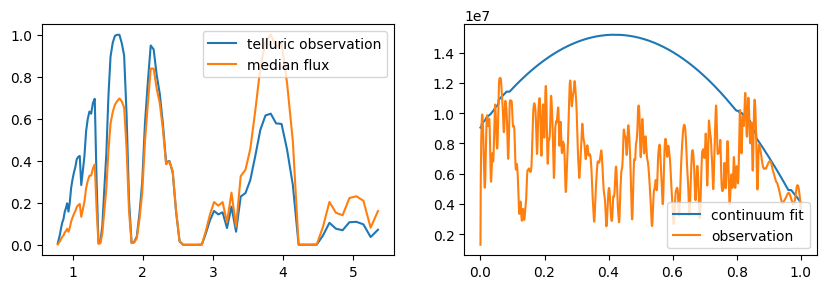

In [7]:
plt.figure(figsize=[10, 3])
plt.subplot(1, 2, 1)
plt.plot(lam_centers, median_telobs/np.max(median_telobs), label='telluric observation')
plt.plot(lam_centers, median_flux/np.max(median_flux), label='median flux')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(xpix, pspec_cont, label='continuum fit')
plt.plot(xpix, observation, label='observation')
plt.legend()

Text(0.5, 0.5, '   J band: 0.37 integrated metric\n\n   H band: 0.85 integrated metric\n\n   K band: 0.75 integrated metric\n\n   L band: 1.67 integrated metric\n\nDiameter: 8.2 m\n\nDistance: 2.0 pc\n\n')

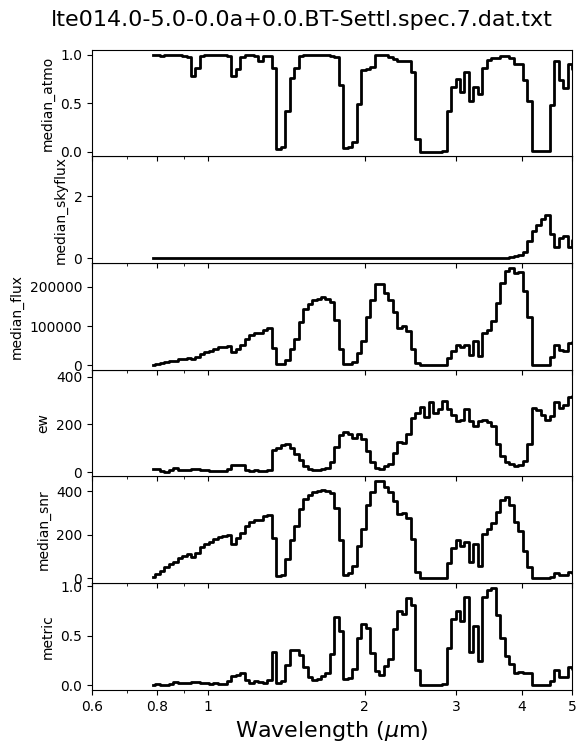

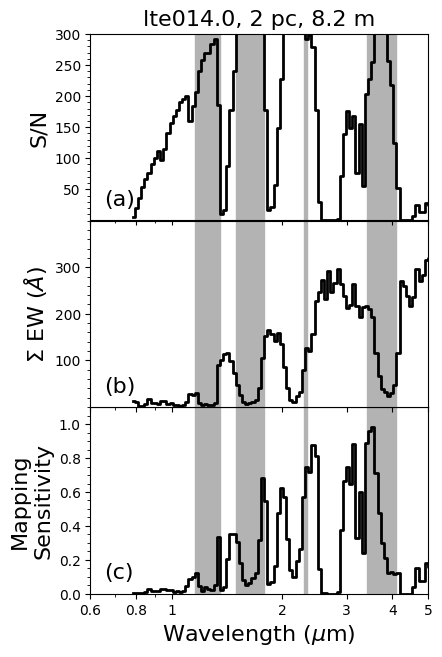

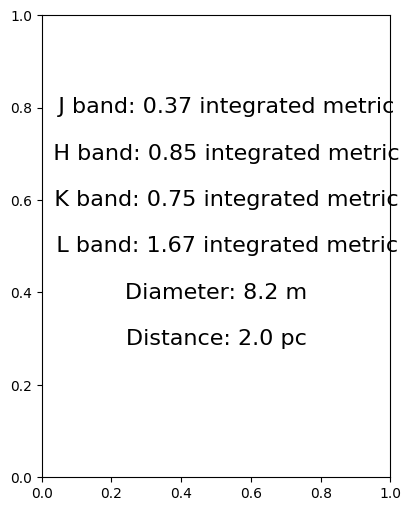

In [16]:
metric = median_snr * ew / 15000. / 1.7

amp_1049b = 0.1
amp = 0.05
metric = (amp / amp_1049b) * median_snr * ew / 25000


xt = [0.6, 0.8, 1, 2, 3, 4, 5]
names = 'metric', 'median_snr', 'ew', 'median_flux','median_skyflux', 'median_atmo'
dy = .8/len(names)

fig = plt.figure(-1, figsize=[6, 8])
fig.text(0.5, 0.93, os.path.split(modelfn)[-1], fontsize=fs, horizontalalignment='center')
for ii, name in enumerate(names):
    ax = plt.subplot(111, position=[.15, .1+ii*dy, .8, dy*0.999])
    exec("plt.semilogx(lam_centers, %s, '-k', drawstyle='steps-mid', linewidth=2)" % name)
    plt.xticks(xt, xt)
    plt.xlim(min(xt), max(xt))
    plt.ylabel(name)
    if ii>0:  
        ax.set_xticklabels([])
    else:
        plt.xlabel('Wavelength ($\mu$m)', fontsize=fs)


names = 'metric', 'ew', 'median_snr', 
ylabs = 'Mapping\nSensitivity', '$\Sigma$ EW $(\AA)$', 'S/N', 
#lims = [0, 30] , [0, 350], [0, 950],
lims = [0, 1.1], [0, 350], [0, 300],
dy = .8/len(names)

fig = plt.figure(-2, [4.5, 7])
band_inds = [1.16, 1.35], [1.5, 1.79], [2, 2.47], [3.4, 4.1]
band_inds = [1.16, 1.35], [1.5, 1.79], [2.288, 2.345], [3.4, 4.1]
band_names = ['J', "H", "K", 'L']
#fig.text(0.5, 0.93, os.path.split(modelfn)[-1], fontsize=fs, horizontalalignment='center')
axs = []
for ii, name in enumerate(names):
    ax = plt.subplot(111, position=[.2, .1+ii*dy, .75, dy*0.999])
    axs.append(ax)
    exec("plt.semilogx(lam_centers, %s, '-k', drawstyle='steps-mid', linewidth=2)" % name)
    plt.xticks(xt, xt)
    plt.xlim(min(xt), max(xt))
    plt.ylabel(ylabs[ii], fontsize=fs)
    plt.ylim(lims[ii])
    plt.minorticks_on()
    if ii>0:  
        ax.set_xticklabels([])
        plt.yticks(ax.get_yticks()[1:])
    else:
        plt.xlabel('Wavelength ($\mu$m)', fontsize=fs)
    if ii<(len(names))-1:  plt.yticks(ax.get_yticks()[0:-1])
    plt.text(.04, .08, '(%s)' % 'abcde'[len(names)-ii-1], fontsize=fs, transform=ax.transAxes)
ax.set_title(f'{os.path.split(modelfn)[-1].split("-")[0]}, {distance} pc, {diameter/100.:.1f} m', fontsize=fs)

def drawRectangle(x,y,width,height,**kw):
    """Draw a rectangle patch on the current, or specified, axes.

    :INPUT:
       x, y -- lower-left corner of rectangle

       width, height -- dimensions of rectangle

    :OPTIONAL INPUT:
       ax -- Axis to draw upon. if None, defaults to current axes.  

       dodraw -- if True, call 'draw()' function to immediately re-draw axes.

       **kw -- options passable to :func:`matplotlib.patches.Rectangle`

     :NOTE:  Axes will NOT auto-rescale after this is called.
      """
    # 2009-09-17 01:33 IJC: Created
    # 2014-03-01 13:51 IJMC: Added 'dodraw' option.
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    
    if 'ax' in kw:
        ax = kw.pop('ax')
    else:
        ax = plt.gca()
    p = mpatches.Rectangle((x,y), width, height, **kw)
    ax.add_patch(p)
    if 'dodraw' in kw and kw['dodraw']: plt.draw()

    return ax, p

for ax in axs:
    for bi in band_inds:
        if min(bi)>1:
            drawRectangle(min(bi), min(ax.get_ylim()), np.diff(bi), np.diff(ax.get_ylim()), ax=ax, color="0.7")


blines = ''
band_integrated_metrics = []
for bi, bn in zip(band_inds, band_names):
    ind = (lam_centers > bi[0]) * (lam_centers <= bi[1])
    val = np.sqrt((metric[ind]**2).sum())
    blines += ('%04s band: %1.2f integrated metric\n' % (bn, val))
    band_integrated_metrics.append(val)

blines += 'Diameter: %1.1f m\nDistance: %1.1f pc\n' % (diameter/100., distance)

fig = plt.figure(figsize=[4.5, 6])
plt.text(0.5, 0.5, blines.replace('\n', '\n\n'), horizontalalignment='center', verticalalignment='center', fontsize=fs)


In [137]:
delta_mmag = 4.6
delta_mag = delta_mmag / 1000.
var_pct = (1 - 10**(-delta_mag / 2.5)) * 100
print(f"peak-to-trough variability {delta_mag:.4f} mag = {var_pct:.3f}%")

peak-to-trough variability 0.0046 mag = 0.423%
